## Author: Gabriel Vance
## Class: DSC550 - Data Mining
## Professor: Dr. Brett Werner
## Date: June 17, 2025

# Purpose: This notebook performs various tasks labeled "Exercises" for Week 6 of the class. Data must be present within the folder that this notebook is run in.
# This week focuses on Feature Selection and Dimensionality Reduction. This exercise focuses on Categorical Feature Selection.
 

In [1]:
# imports
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.feature_selection import SelectKBest, chi2
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.feature_selection import SelectKBest, chi2


# Load the dataset
data = pd.read_csv('mushrooms.csv')

# Convert the categorical features (all of them) to dummy variables.

In [2]:
data_dummies = pd.get_dummies(data)
data_dummies.head()

,class_e,class_p,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,False,True,False,False,False,False,False,True,False,False,...,True,False,False,False,False,False,False,False,True,False
1,True,False,False,False,False,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,False
2,True,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
3,False,True,False,False,False,False,False,True,False,False,...,True,False,False,False,False,False,False,False,True,False
4,True,False,False,False,False,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,False


## Split the data into a training and test set.

In [3]:
# Separate features (X) and target variable (y)
X = data_dummies.drop('class_e', axis=1)  # Drop the target column from feature set
y = data_dummies['class_e']               # Target variable for prediction

# Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


## Fit a decision tree classifier on the training set.


In [4]:
# Initialize the Decision Tree Classifier with a fixed random state for reproducibility
dtc = DecisionTreeClassifier(random_state=42)

# Train the classifier on the training data
dtc.fit(X_train, y_train)


DecisionTreeClassifier(random_state=42)

## Report the accuracy and create a confusion matrix for the model prediction on the test set.


In [5]:
# Use the trained decision tree to predict labels for the test set
y_pred = dtc.predict(X_test)

# Calculate and print the accuracy of the predictions
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# Generate and print the confusion matrix to evaluate prediction performance
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)


Accuracy: 1.0000
Confusion Matrix:
[[782   0]
 [  0 843]]


## Create a visualization of the decision tree.

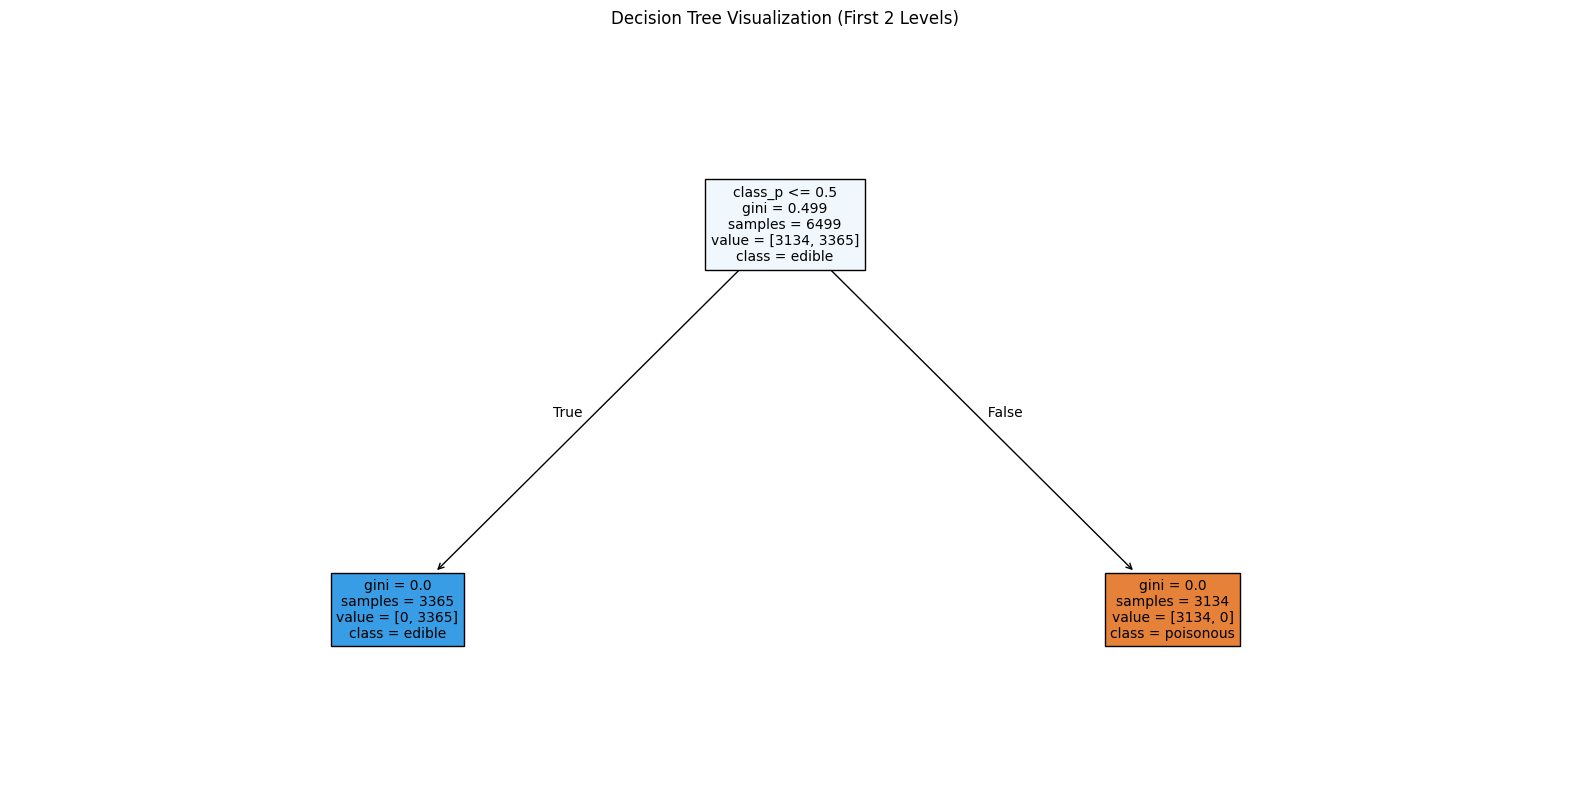

In [6]:
# Set figure size for better readability
plt.figure(figsize=(20, 10))

# Visualize the decision tree up to depth 2 with feature and class names, and color-filled nodes
plot_tree(
    dtc,
    feature_names=X.columns,
    class_names=['poisonous', 'edible'],
    filled=True,
    max_depth=2,
    fontsize=10
)

# Add a title to the plot
plt.title("Decision Tree Visualization (First 2 Levels)")

# Display the plot
plt.show()


## Use a χ2-statistic selector to pick the five best features for this data

In [7]:
# Initialize SelectKBest with chi-squared test to select top 5 features
selector = SelectKBest(score_func=chi2, k=5)

# Fit selector on the training data to identify best features
selector.fit(X_train, y_train)

# Retrieve the names of the selected features
selected_features = X_train.columns[selector.get_support()]


## Which five features were selected in step 7?

In [8]:
print("Top 5 features selected by chi2:", list(selected_features))

Top 5 features selected by chi2: ['class_p', 'odor_f', 'odor_n', 'stalk-surface-above-ring_k', 'stalk-surface-below-ring_k']


## Repeat steps 4 and 5 with the five best features selected in step 7.

In [9]:
# Use only the top 5 selected features
X_train_top5 = X_train[selected_features]
X_test_top5 = X_test[selected_features]

# Fit a decision tree classifier
dtc_top5 = DecisionTreeClassifier(random_state=42)
dtc_top5.fit(X_train_top5, y_train)

# Predict on the test set
y_pred_top5 = dtc_top5.predict(X_test_top5)

# Calculate accuracy
accuracy_top5 = accuracy_score(y_test, y_pred_top5)
print(f"Accuracy with top 5 features: {accuracy_top5:.4f}")

# Create confusion matrix
cm_top5 = confusion_matrix(y_test, y_pred_top5)
print("Confusion Matrix with top 5 features:")
print(cm_top5)

Accuracy with top 5 features: 1.0000
Confusion Matrix with top 5 features:
[[782   0]
 [  0 843]]


In [ ]:
print("Summary of Findings:\n\n")
print(f"Initial Decision Tree Accuracy (all features): {accuracy:.4f}")
print(f"Confusion Matrix (all features):\n{cm}")
print()
print("Top 5 features selected by chi2:", list(selected_features))
print()
print(f"Decision Tree Accuracy (top 5 features): {accuracy_top5:.4f}")
print(f"Confusion Matrix (top 5 features):\n{cm_top5}")
print()
print("Both models achieved perfect accuracy on the test set. Using only the top 5 features selected by the chi-squared test did not reduce model performance, indicating these features are highly predictive for this dataset.")

Summary of Findings:


Initial Decision Tree Accuracy (all features): 1.0000
Confusion Matrix (all features):
[[782   0]
 [  0 843]]

Top 5 features selected by chi2: ['class_p', 'odor_f', 'odor_n', 'stalk-surface-above-ring_k', 'stalk-surface-below-ring_k']

Decision Tree Accuracy (top 5 features): 1.0000
Confusion Matrix (top 5 features):
[[782   0]
 [  0 843]]

Both models achieved perfect accuracy on the test set. Using only the top 5 features selected by the chi-squared test did not reduce model performance, indicating these features are highly predictive for this dataset.


: 